Dataset loading and description

In [3]:
df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (395, 33)
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 33 columns]
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu

Data inspection and cleaning

In [4]:
# Check the number of rows and columns
print(df.shape)

# Check column names and data types
df.info()

# Count missing values in each column
print(df.isnull().sum())

# Count duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check the distribution of the target grade
print(df["G3"].describe())

(395, 33)
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  

Exploratory data analysis

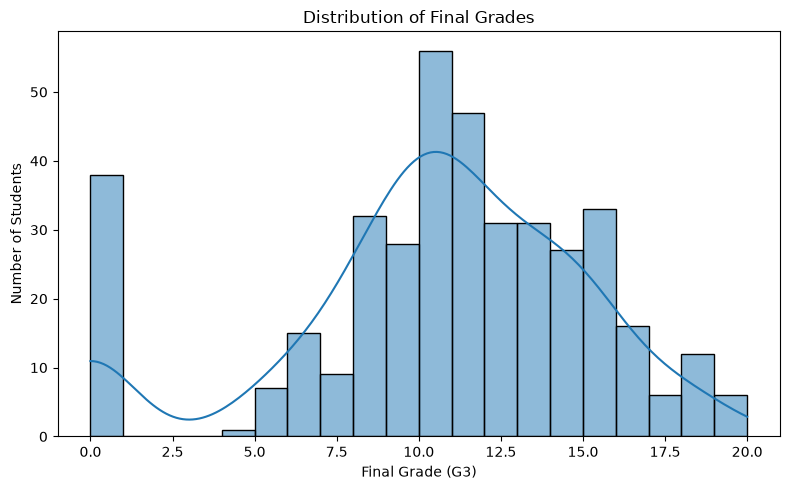

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(df["G3"], bins=20, kde=True)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

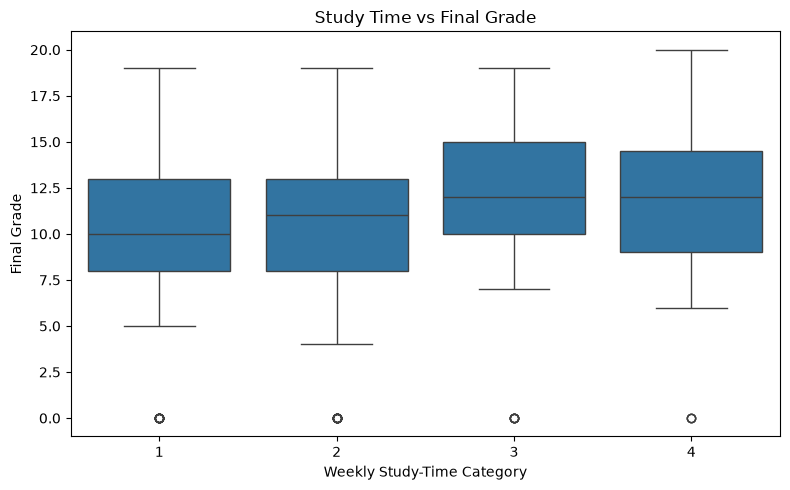

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Weekly Study-Time Category")
plt.ylabel("Final Grade")
plt.tight_layout()
plt.show()

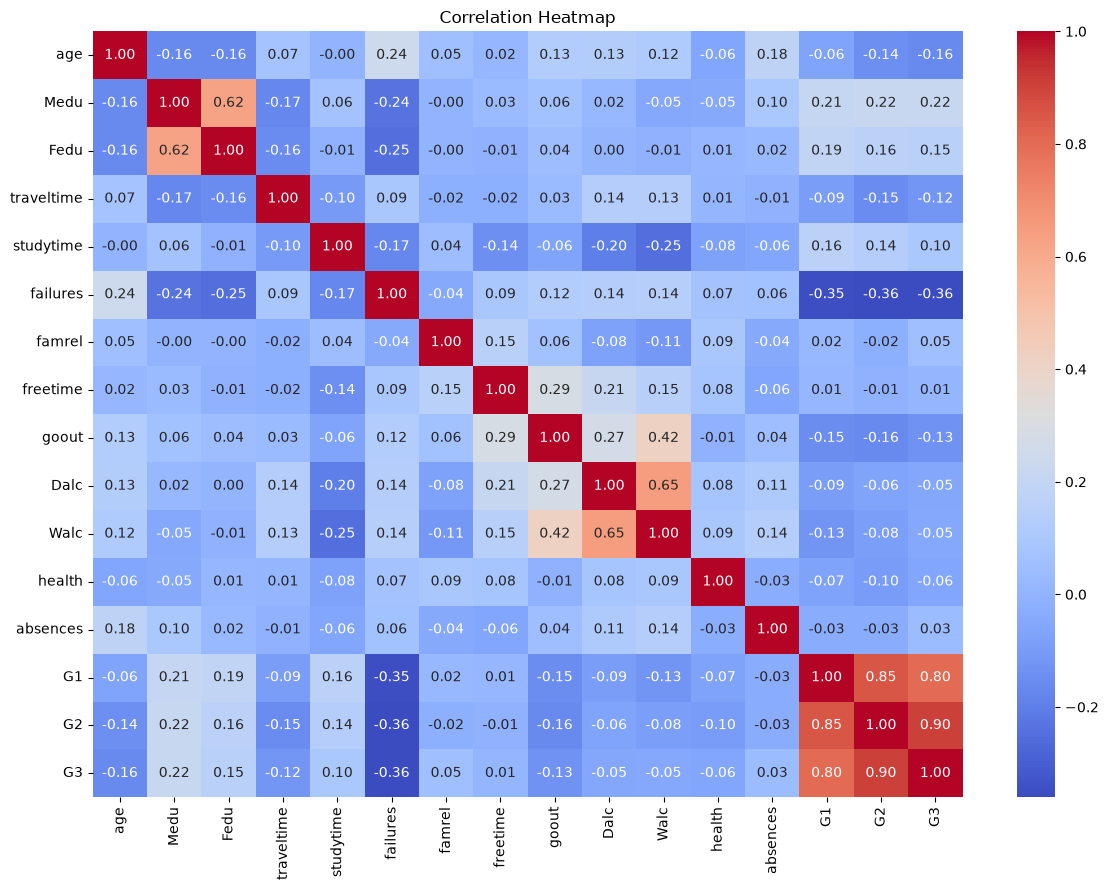

In [8]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 9))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

Feature selection and target definition

In [9]:
# Final grade is the target
y = df["G3"]

# Remove the target and earlier grades from the inputs
X = df.drop(columns=["G3", "G1", "G2"])

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (395, 30)
Target: (395,)


In [20]:
# Identify numerical features
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(
    include=["str", "object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']
Categorical features: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


Train-test split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 316
Testing samples: 79


Data preprocessing and Training decision tree regression model

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str","object", "category", "bool"]
).columns.tolist()


# Preprocessing for numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])


# Preprocessing for categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])


# Combine both preprocessing steps
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# Complete Decision Tree regression pipeline
tree_model = Pipeline(steps=[
    ("preprocessing", tree_preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=4,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    ))
])


# Train the model
tree_model.fit(X_train, y_train)

# Predict on test data
y_pred_tree = tree_model.predict(X_test)

print("First 10 predicted grades:")
print(y_pred_tree[:10])

First 10 predicted grades:
[ 7.         11.7421875  11.         11.7421875  10.         10.15384615
 11.7421875  11.7421875  10.88888889 11.7421875 ]


Evaluation using MAE, RMSE, and \(R^2\)

In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_tree = mean_absolute_error(y_test, y_pred_tree)
rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))
r2_tree = r2_score(y_test, y_pred_tree)

print("MAE:", round(mae_tree, 3))
print("RMSE:", round(rmse_tree, 3))
print("R² Score:", round(r2_tree, 3))

MAE: 3.543
RMSE: 4.465
R² Score: 0.028


Compare the baseline and Decision Tree

In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create the baseline model
baseline_model = DummyRegressor(strategy="mean")

# Train the model using training target values
baseline_model.fit(X_train, y_train)

# Predict grades for the test data
y_pred_baseline = baseline_model.predict(X_test)

# Calculate evaluation metrics
mae_baseline = mean_absolute_error(y_test, y_pred_baseline)

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, y_pred_baseline)
)

r2_baseline = r2_score(y_test, y_pred_baseline)

print("Baseline Model: Dummy Regressor")
print("MAE:", round(mae_baseline, 3))
print("RMSE:", round(rmse_baseline, 3))
print("R² Score:", round(r2_baseline, 3))

Baseline Model: Dummy Regressor
MAE: 3.646
RMSE: 4.55
R² Score: -0.01


             Model    MAE   RMSE  R2 Score
0  Dummy Regressor  3.646  4.550    -0.010
1    Decision Tree  3.543  4.465     0.028


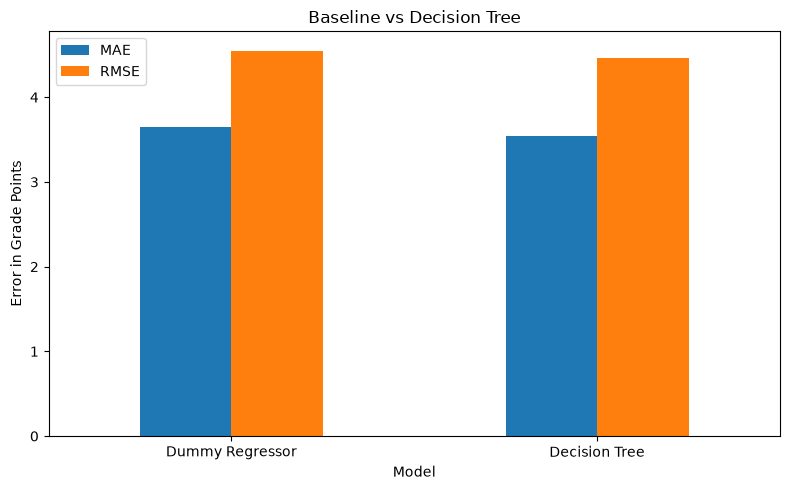

In [15]:
# Create a comparison table
comparison = pd.DataFrame({
    "Model": ["Dummy Regressor", "Decision Tree"],
    "MAE": [mae_baseline, mae_tree],
    "RMSE": [rmse_baseline, rmse_tree],
    "R2 Score": [r2_baseline, r2_tree]
})

print(comparison.round(3))
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Baseline vs Decision Tree")
plt.ylabel("Error in Grade Points")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

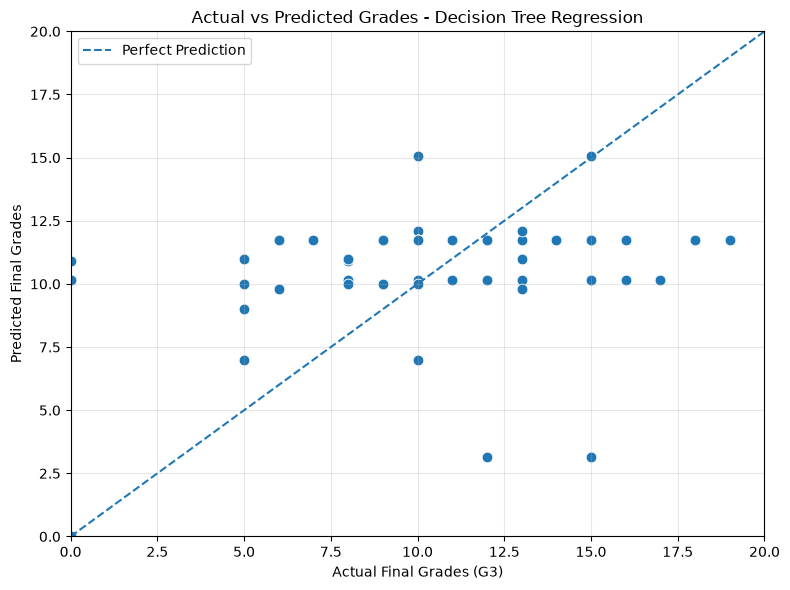

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot actual grades against predicted grades
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred_tree,
    s=60
)

# Reference line for perfect predictions
plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Final Grades (G3)")
plt.ylabel("Predicted Final Grades")
plt.title("Actual vs Predicted Grades - Decision Tree Regression")

plt.xlim(0, 20)
plt.ylim(0, 20)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()